# 02 · Fourier transforms: spatial patterns and frequency

A Fourier transform answers a practical optics question: which spatial frequencies make up a measured or modeled pattern? We use two sinusoids so the peaks have known locations.

This is the package-user version: imports come first, and each operation is introduced when the physical question calls for it.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Build a sampled signal

The sample spacing sets the largest frequency we can represent; the total sampled width sets frequency resolution.

In [ ]:
dx_m = 1e-3
width_m = 1.0
x_m = np.arange(-width_m/2, width_m/2, dx_m)
signal = np.sin(2*np.pi*20*x_m) + 0.5*np.sin(2*np.pi*5*x_m)


## 2. Read the spectrum

The magnitude shows how strongly each spatial frequency contributes. A real signal has symmetric positive and negative frequency peaks.

In [ ]:
freq_cpm = np.fft.fftshift(np.fft.fftfreq(x_m.size, d=dx_m))
spectrum = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(signal)))


## 3. Reconstruct the sampled signal

The inverse transform should recover the original samples, up to floating-point precision.

In [ ]:
reconstructed = np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(spectrum))).real
print("Maximum reconstruction error:", np.max(np.abs(reconstructed - signal)))


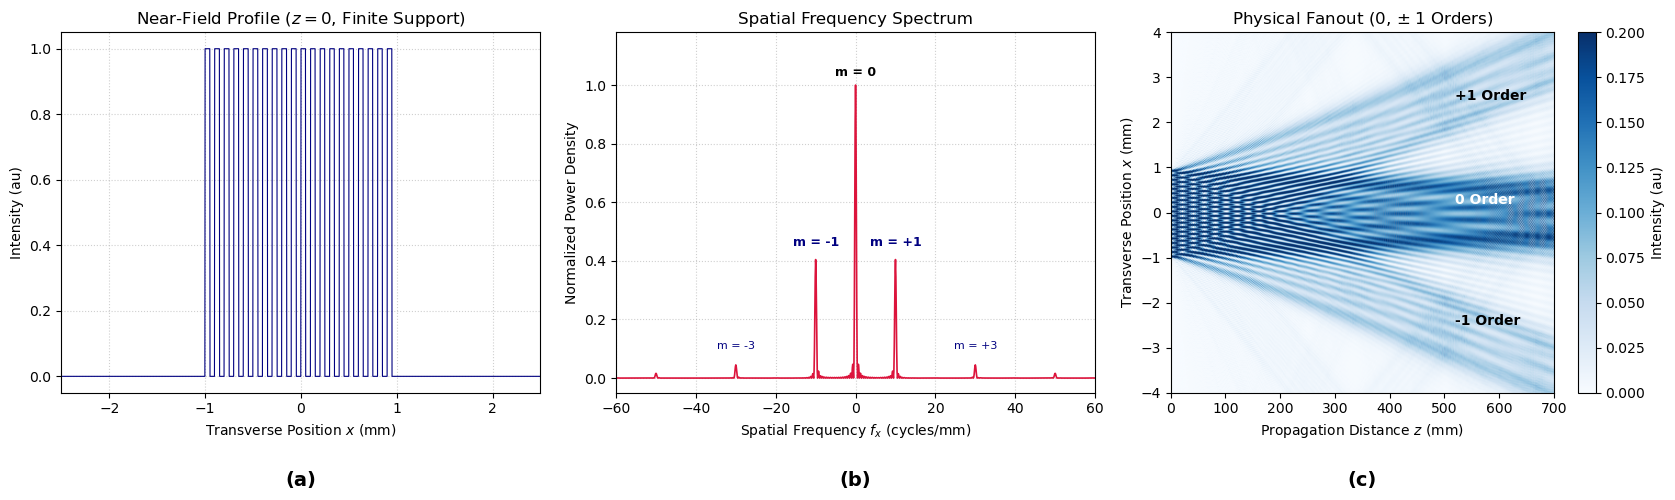

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Grid and physical parameters
L_m = 10e-3  # 10 mm transverse window
M = 4096  # Sampling points for high square-wave resolution
dx_m = L_m / M  # Spatial resolution
x_m = np.linspace(-L_m / 2, L_m / 2, M)

wavelength_m = 500e-9  # 500 nm wavelength
period_m = 100e-6  # 100 um grating period (d)

# 2. Finite-support Square Hat Envelope & Binary Grating (Half size: 2 mm wide)
envelope_width_m = 2.0e-3  # 2 mm wide square hat envelope (-1 mm to +1 mm)
envelope = (np.abs(x_m) <= envelope_width_m / 2).astype(float)
grating = (np.sin(2 * np.pi * x_m / period_m) >= 0).astype(float)
E_out = envelope * grating  # Field immediately after grating

# 3. Propagate along Z using Fresnel/Angular Spectrum method (Doubled distance: 700 mm)
Z_m = np.linspace(0, 0.70, 350)  # 0 to 70 cm propagation
I_xz = np.zeros((len(Z_m), M))

# Spatial frequency grid centered at 0 Hz
fx = np.fft.fftshift(np.fft.fftfreq(M, dx_m))  # cycles / meter

# Transform initial field to spatial frequency domain (Fourier Spectrum)
U_f0 = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(E_out))) * dx_m

for idx, z in enumerate(Z_m):
  # Paraxial Fresnel transfer function H(fx)
  H = np.exp(-1j * np.pi * wavelength_m * z * (fx**2))

  # Propagate in spatial frequency domain and invert back
  U_fz = U_f0 * H
  U_z = np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(U_fz))) / dx_m
  I_xz[idx, :] = np.abs(U_z) ** 2

# 4. Plot 3-Panel Figure
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel 1: Near-field modulation
axes[0].plot(x_m * 1e3, np.abs(E_out) ** 2, color="navy", lw=0.8)
axes[0].set_xlim(-2.5, 2.5)
axes[0].set_title("Near-Field Profile ($z = 0$, Finite Support)")
axes[0].set_xlabel("Transverse Position $x$ (mm)")
axes[0].set_ylabel("Intensity (au)")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Panel 2: Discrete Spatial Frequency Spectrum
fx_kmm = fx / 1e3  # Convert to cycles / mm
spectrum_power = np.abs(U_f0) ** 2
axes[1].plot(
    fx_kmm, spectrum_power / np.max(spectrum_power), color="crimson", lw=1.2
)
axes[1].set_xlim(-60, 60)
axes[1].set_ylim(-0.05, 1.18)
axes[1].set_title("Spatial Frequency Spectrum")
axes[1].set_xlabel("Spatial Frequency $f_x$ (cycles/mm)")
axes[1].set_ylabel("Normalized Power Density")
axes[1].grid(True, linestyle=":", alpha=0.6)

fg = 1 / period_m / 1e3
axes[1].annotate("m = 0", xy=(0, 1.03), ha="center", fontsize=9, fontweight="bold")
axes[1].annotate(
    "m = +1", xy=(fg, 0.45), ha="center", fontsize=9, fontweight="bold", color="navy"
)
axes[1].annotate(
    "m = -1",
    xy=(-fg, 0.45),
    ha="center",
    fontsize=9,
    fontweight="bold",
    color="navy",
)
axes[1].annotate(
    "m = +3", xy=(3 * fg, 0.10), ha="center", fontsize=8, color="navy"
)
axes[1].annotate(
    "m = -3", xy=(-3 * fg, 0.10), ha="center", fontsize=8, color="navy"
)

# Panel 3: Longitudinal Fanout
im = axes[2].imshow(
    I_xz.T / np.max(I_xz),
    extent=[Z_m[0] * 1e3, Z_m[-1] * 1e3, x_m[0] * 1e3, x_m[-1] * 1e3],
    aspect="auto",
    origin="lower",
    cmap="Blues",
    vmax=0.2,
)
axes[2].set_ylim(-4, 4)
axes[2].set_xlim(0, 700)  # Matches Z_m max (700 mm)
axes[2].set_title("Physical Fanout ($0, \pm 1$ Orders)")
axes[2].set_xlabel("Propagation Distance $z$ (mm)")
axes[2].set_ylabel("Transverse Position $x$ (mm)")
plt.colorbar(im, ax=axes[2], label="Intensity (au)")

axes[2].annotate(
    "+1 Order", xy=(520, 2.5), color="black", fontweight="bold"
)
axes[2].annotate("0 Order", xy=(520, 0.2), color="white", fontweight="bold")
axes[2].annotate("-1 Order", xy=(520, -2.5), color="black", fontweight="bold")

plt.tight_layout(rect=[0, 0.08, 1, 1])

# Add bold (a), (b), (c) labels centered beneath each plot
labels = ["(a)", "(b)", "(c)"]
for i, ax in enumerate(axes):
  pos = ax.get_position()
  fig.text(
      pos.x0 + pos.width / 2,
      0.01,
      labels[i],
      ha="center",
      va="bottom",
      fontweight="bold",
      fontsize=14,
  )


plt.show()